# Investigación · Equipo 2

| Campo | Dato |
|---|---|
| Curso y grupo | MA2015.201 |
| Equipo | Equipo 2 |
| Integrantes | Alejandro Daniel Bailón Mena · Patricio Hernández Campuzano · Daniel Otero Calderón |
| Avance | Investigación (A1 y A2) · versión 1 · 10/10/2026 |
| Base común | `reto_planta_fisica_solucion_minima.ipynb`, `pyproject.toml` y `uv.lock` del kit (versión 2026-10-03) |

Esta libreta es la **base común sin modificar** más las evidencias de nuestro equipo. Todas las celdas que añadimos empiezan con **«Investigación ·»** para distinguirlas de la base.

## Investigación · Rotación de responsabilidades

Registramos solo las rotaciones que realmente ocurrieron.

| Tarea | Programó | Revisó | Verificó (reprodujo) |
|---|---|---|---|
| Formulación y supuestos (A1) | Alejandro Daniel Bailón Mena | Daniel Otero Calderón | Patricio Hernández Campuzano |
| Cálculo manual de (6, 6, 6, 6) | Alejandro Daniel Bailón Mena | Patricio Hernández Campuzano | Daniel Otero Calderón |
| Desglose programado `calculo_manual` y `comparar` | Patricio Hernández Campuzano | Alejandro Daniel Bailón Mena | Daniel Otero Calderón |
| Comparación con `evaluate` y caso máximo | Alejandro Daniel Bailón Mena | Patricio Hernández Campuzano | Daniel Otero Calderón |
| Ejecución limpia desde kernel reiniciado | — | — | Daniel Otero Calderón, 10/10/2026 |

## Investigación · Cambios respecto de la base común

| Cambio | Motivo |
|---|---|
| **No modificamos ninguna celda de la base**: se conservan su texto, su código (incluido `evaluate`) y su orden. | La consigna pide conservar las secciones de la base. |
| Añadimos celdas de evidencia junto al contenido pertinente: formulación después de la sección 1, cálculo manual en la sección 2, comparación e interpretación después de los casos de `evaluate`. | Organizar los cuatro apartados de Investigación. |
| Añadimos nombres en español (`D`, `Q`, `C`, `TOL`, `k_max`, `edificios`) que **apuntan** a las constantes de la base (`DEMAND`, `CAPACITY`, `LIMITS`, `BUILDINGS`); no definen datos nuevos. | Que nuestras fórmulas se lean igual que en la formulación. |
| Integramos el avance de Patricio Hernández Campuzano (`calculo_manual` y `comparar`). Su celda leía `datos_marzo_2025.csv` y fallaba con `FileNotFoundError`; ahora toma los datos de la base y ya no necesita el CSV. Imprime $F$ con 6 decimales y guarda sus resultados como `desglose`. | La base ya integra los datos; un solo redondeo declarado; no sobrescribir la tabla de contraste. |

### Dónde está cada evidencia de la rúbrica

| Criterio | Evidencia | Celda |
|---|---|---|
| A1 | Qué decide cada gen; nivel, fracción y volumen | *Investigación · Formulación* → A1.1 |
| A1 | Orden, genes enteros, dominios y $x_i = k_i/10$ | A1.2 |
| A1 | Demandas de marzo 2025, unidades y procedencia | A1.3 y su celda de código |
| A1 | Objetivo, fórmulas y dirección de la aptitud | A1.4 |
| A1 | Capacidad de 1410 m³, máximos didácticos y alcance | A1.5 |
| A2 | Aritmética de (6, 6, 6, 6) con sustituciones y unidades | *Investigación · Cálculo manual* |
| A2 | Contraste con `evaluate` de las cinco claves y redondeo | *Investigación · Comparación con evaluate* |
| A2 | Caso máximo (8, 8, 6, 8): por qué respeta dominios y es infactible | *Investigación · Interpretación y correcciones* |

# Planta Física: aprendemos algoritmos genéticos con cuatro decisiones

MA2015.201 · Marzo de 2025 · Una libreta acumulativa.

Construimos un modelo, seguimos una generación y comparamos dos configuraciones pequeñas. Conserva aquí los cálculos, el código y la interpretación de tu equipo.

## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

# Investigación · Formulación y supuestos (A1)

## A1.1 El problema y la decisión

Cada edificio necesita en marzo una cantidad fija de agua, su demanda $D_i$ en m³. Esa demanda se cubre con dos fuentes: **agua tratada** (reúso) y **agua potable**. Lo único que decidimos es **qué porcentaje de la demanda de cada edificio se cubre con agua tratada**; el resto se cubre automáticamente con agua potable. Por eso hay cuatro decisiones, una por edificio, y cada una es un gen del cromosoma $k = (k_1, k_2, k_3, k_4)$.

- **Datos fijos:** las cuatro demandas $D_i$, su total $Q = 2276.21$ m³ y la capacidad $C = 1410$ m³.
- **Lo que decide el algoritmo:** solo los cuatro niveles $k_i$.

Un gen no es un volumen ni un porcentaje: es un **nivel entero** que se convierte en fracción y después en volumen.

| Concepto | Símbolo | Tipo y unidad | Ejemplo con $k_i = 6$ en Aulas 1 |
|---|---|---|---|
| Nivel (gen) | $k_i$ | entero, sin unidades | 6 |
| Fracción de reúso | $x_i = k_i/10$ | real en $[0, 1]$, sin unidades | 0.60, es decir 60 % |
| Volumen tratado | $T_i = D_i\,x_i$ | m³ | 847.00 × 0.60 = 508.2 m³ |
| Volumen potable | $P_i = D_i - T_i$ | m³ | 847.00 − 508.2 = 338.8 m³ |

## A1.2 Orden del cromosoma, genes enteros y dominios

Conservamos este orden en tablas, cromosoma y código; coincide con `BUILDINGS`, `DEMAND` y `LIMITS` de la base.

| Posición | Edificio | Gen | Dominio entero de $k_i$ | Fracción $x_i$ | Reúso máximo |
|---:|---|---|---|---|---:|
| 1 | Aulas 1 | $k_1$ | $\{0, 1, \dots, 8\}$ | $\{0, 0.1, \dots, 0.8\}$ | 80 % |
| 2 | Biblioteca | $k_2$ | $\{0, 1, \dots, 8\}$ | $\{0, 0.1, \dots, 0.8\}$ | 80 % |
| 3 | Cedetec | $k_3$ | $\{0, 1, \dots, 6\}$ | $\{0, 0.1, \dots, 0.6\}$ | 60 % |
| 4 | Aulas 2 | $k_4$ | $\{0, 1, \dots, 8\}$ | $\{0, 0.1, \dots, 0.8\}$ | 80 % |

Cada nivel vale diez puntos porcentuales: $x_i = k_i/10$ y el porcentaje es $100\,x_i$. El gen **nunca** se usa directamente como fracción: $k_i = 6$ significa 60 %, no 600 %.

Un cromosoma con valores no enteros (por ejemplo 6.5) o fuera de su dominio (por ejemplo $k_3 = 8$) **no es un candidato**: `evaluate` lo rechaza sin redondearlo ni corregirlo. Es distinto de un candidato válido que rebasa la capacidad, que sí se evalúa con la rama penalizada (A1.4). En total hay $9 \times 9 \times 7 \times 9 = 5103$ cromosomas válidos.

## A1.3 Datos: demandas de marzo de 2025

| Pos. | Edificio | Predio | Potable observada (m³) | Tratada observada (m³) | Demanda $D_i$ (m³) |
|---:|---|---|---:|---:|---:|
| 1 | Aulas 1 | Puente 222 | 200.00 | 647.00 | **847.00** |
| 2 | Biblioteca | Puente 222 | 145.00 | 317.00 | **462.00** |
| 3 | Cedetec | Puente 222 | 99.50 | 184.71 | **284.21** |
| 4 | Aulas 2 | Periférico 6666 | 394.00 | 289.00 | **683.00** |
| | **Total** | | 838.50 | 1437.71 | $Q$ = **2276.21** |

**Procedencia.** Son los **consumos observados** de marzo de 2025, agregados por edificio. Provienen de `consumo_agua_2023_2026.csv` del kit (filas `anio = 2025`, `mes_num = 3`), que a su vez se preparó a partir del libro de Planta Física `consumo-agua.xlsx` con fecha de corte 2026-08-21. La demanda de cada edificio es `potable_m3 + tratada_m3`. La base guarda estos cuatro registros y los hashes SHA-256 de los archivos fuente en su metadata (`monthly_case`). Comprobamos que esos hashes coinciden con los de nuestras copias del kit, así que la base usa exactamente esos datos. En los cuatro registros **ninguna bandera está activa**: no hay imputaciones, ceros ni posibles anomalías.

La celda siguiente vuelve a sumar los registros observados y comprueba que dan las demandas de la base.

In [2]:
# Investigación · Nombres de la formulación (apuntan a las constantes de la base)
D = DEMAND                          # m³, demandas de marzo 2025
Q = float(DEMAND.sum())             # m³, demanda total
C = CAPACITY                        # m³, capacidad didáctica
TOL = 1e-8                          # m³, tolerancia de capacidad (la misma que usa evaluate)
k_max = LIMITS.tolist()             # niveles máximos por edificio
edificios = ["Aulas 1", "Biblioteca", "Cedetec", "Aulas 2"]

# Registros observados de marzo 2025 (consumo_agua_2023_2026.csv), mismo orden que BUILDINGS
potable_obs = np.array([200.00, 145.00, 99.50, 394.00])   # m³
tratada_obs = np.array([647.00, 317.00, 184.71, 289.00])   # m³

print("DATOS DE MARZO 2025")
for i in range(4):
    print(f"  {i + 1}. {edificios[i]:<11} D = {potable_obs[i]:7.2f} + {tratada_obs[i]:7.2f} "
          f"= {D[i]:7.2f} m³   k de 0 a {k_max[i]}")
print(f"  Q = {D[0]:.2f} + {D[1]:.2f} + {D[2]:.2f} + {D[3]:.2f} = {Q:.2f} m³")
print(f"  C = {C:.0f} m³ (supuesto didáctico)")
print("\n¿Potable + tratada observadas = DEMAND de la base?",
      np.allclose(potable_obs + tratada_obs, D, atol=1e-9, rtol=0))
print(f"Agua tratada observada en marzo 2025: {tratada_obs.sum():.2f} m³ frente a C = {C:.0f} m³")

DATOS DE MARZO 2025
  1. Aulas 1     D =  200.00 +  647.00 =  847.00 m³   k de 0 a 8
  2. Biblioteca  D =  145.00 +  317.00 =  462.00 m³   k de 0 a 8
  3. Cedetec     D =   99.50 +  184.71 =  284.21 m³   k de 0 a 6
  4. Aulas 2     D =  394.00 +  289.00 =  683.00 m³   k de 0 a 8
  Q = 847.00 + 462.00 + 284.21 + 683.00 = 2276.21 m³
  C = 1410 m³ (supuesto didáctico)

¿Potable + tratada observadas = DEMAND de la base? True
Agua tratada observada en marzo 2025: 1437.71 m³ frente a C = 1410 m³


## A1.4 Objetivo, fórmulas y dirección de la aptitud

Para un cromosoma válido $k$:

$$T_i = D_i\,\frac{k_i}{10}, \qquad P_i = D_i - T_i \qquad (\text{m}^3)$$

$$T = \sum_{i=1}^{4} T_i, \qquad P = Q - T, \qquad E = \max(0,\; T - C) \qquad (\text{m}^3)$$

$$F(k) = \begin{cases} \dfrac{P}{Q}, & T \le C \quad (\text{factible})\\[2mm] 1 + \dfrac{E}{C}, & T > C \quad (\text{infactible}) \end{cases}$$

- $T_i$ y $P_i$ son los volúmenes tratado y potable del edificio $i$; $T$ y $P$, sus totales; $E$, el exceso sobre la capacidad. Todos en m³.
- **Objetivo:** minimizar el agua potable $P$ sujeto a los dominios y a $T \le C$. Minimizamos potable porque es el recurso que se quiere ahorrar: cada m³ cubierto con agua tratada es un m³ de potable que no se consume.
- **Aptitud sin unidades, menor es mejor.** Si el plan es factible, $F = P/Q$ es la fracción de la demanda que sigue siendo potable, entre 0 y 1. Si es infactible, $F = 1 + E/C$ siempre es mayor que 1. Así, **cualquier candidato factible queda por delante de cualquier infactible**, y entre infactibles se prefiere el que rebasa menos la capacidad.
- **Tolerancia:** un candidato cumple la capacidad cuando $E \le 10^{-8}$ m³, para que el error de punto flotante no vuelva infactible un caso límite.

## A1.5 Capacidad, máximos didácticos y alcance

| Elemento | Valor | Naturaleza | Fuente |
|---|---|---|---|
| Demandas $D_i$ | tabla A1.3 | **Dato observado** | Libro de Planta Física, vía `consumo_agua_2023_2026.csv` |
| Capacidad $C$ | 1410 m³ | **Supuesto didáctico** | `parametros_reto.csv`, calibración docente, estado `supuesto_didactico_aprobado`. No es una capacidad confirmada por Planta Física. |
| Máximo 80 % en Aulas 1, Biblioteca y Aulas 2 | $k_i \le 8$ | **Supuesto didáctico** | Base común y guía del reto |
| Máximo 60 % en Cedetec | $k_3 \le 6$ | **Supuesto didáctico** | Base común y guía del reto |
| Pasos de 10 puntos | $k_i$ entero | **Supuesto didáctico** | Base común y guía del reto |

**El consumo observado no demuestra la capacidad.** En marzo de 2025 se consumieron 1437.71 m³ de agua tratada, más que los 1410 m³ adoptados. No es una contradicción: $C$ no se dedujo del consumo, es un límite fijado para el ejercicio. Por eso no afirmamos que la planta real produzca 1410 m³, ni que los máximos por edificio estén validados por el socio.

**Alcance.** El modelo es **mensual y estático**: un mes (marzo de 2025), cuatro edificios y una restricción de capacidad. Los resultados describen un modelo académico; no son una recomendación hidráulica o sanitaria validada ni una instrucción operativa para el campus.

## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

# Investigación · Cálculo manual (A2)

**Candidato:** $k = (6, 6, 6, 6)$. Es válido porque los cuatro genes son enteros; $6 \le 8$ en Aulas 1, Biblioteca y Aulas 2; y $6 \le 6$ en Cedetec. Lo calculamos **antes** de ejecutar `evaluate`.

**Redondeo declarado:** calculamos con todos los decimales y presentamos volúmenes con 3 decimales (m³) y la aptitud con 6 decimales. No redondeamos resultados intermedios.

### Sustituciones por edificio

| Pos. | Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i = D_i x_i$ (m³) | $P_i = D_i - T_i$ (m³) |
|---:|---|---:|---:|---:|---:|---:|
| 1 | Aulas 1 | 847.00 | 6 | 0.60 | 847.00 × 0.60 = **508.200** | 847.00 − 508.200 = **338.800** |
| 2 | Biblioteca | 462.00 | 6 | 0.60 | 462.00 × 0.60 = **277.200** | 462.00 − 277.200 = **184.800** |
| 3 | Cedetec | 284.21 | 6 | 0.60 | 284.21 × 0.60 = **170.526** | 284.21 − 170.526 = **113.684** |
| 4 | Aulas 2 | 683.00 | 6 | 0.60 | 683.00 × 0.60 = **409.800** | 683.00 − 409.800 = **273.200** |

### Totales, exceso, factibilidad y aptitud

- $T = 508.200 + 277.200 + 170.526 + 409.800 = \mathbf{1365.726}$ m³
- $P = Q - T = 2276.21 - 1365.726 = \mathbf{910.484}$ m³
- $E = \max(0,\; 1365.726 - 1410) = \max(0,\; -44.274) = \mathbf{0}$ m³
- **Factibilidad:** $T = 1365.726 \le 1410 = C$ → **factible**, con 44.274 m³ de capacidad sin usar.
- **Aptitud (rama factible):** $F = P/Q = 910.484 / 2276.21 = \mathbf{0.400000}$, sin unidades.

### Comprobaciones

- $T_i + P_i = D_i$: 508.200 + 338.800 = 847.00; 277.200 + 184.800 = 462.00; 170.526 + 113.684 = 284.21; 409.800 + 273.200 = 683.00 ✓
- $\sum P_i = 338.800 + 184.800 + 113.684 + 273.200 = 910.484 = P$ ✓
- $T + P = 1365.726 + 910.484 = 2276.21 = Q$ ✓
- Como los cuatro edificios usan la misma fracción, $P/Q$ debe ser $1 - 0.60 = 0.40$ ✓

**¿Por qué cumple la capacidad?** Con 60 % en todos los edificios se pide el 60 % de la demanda total: $0.60 \times 2276.21 = 1365.726$ m³, que está por debajo de los 1410 m³ disponibles.

### Desglose programado del mismo cálculo

La celda siguiente es el avance de Patricio Hernández Campuzano. Repite el cálculo paso a paso e imprime cada sustitución. Valida los genes, calcula $T_i$ y $P_i$, suma de dos en dos, obtiene $P$ por dos caminos ($Q - T$ y $\sum P_i$), calcula $E$ y aplica la rama de aptitud que corresponde. Es una **segunda comprobación** de la aritmética; la evidencia manual es la tabla anterior.

In [3]:
# Investigación · Avance de Patricio Hernández Campuzano: desglose paso a paso
# Redondeo: se calcula con toda la precisión; al mostrar, m³ con 3 decimales y F con 6.
def calculo_manual(k):
    print(f"CANDIDATO k = ({k[0]}, {k[1]}, {k[2]}, {k[3]})")
    print("=" * 60)

    # 1) Validez de los genes
    for i in range(4):
        if k[i] != int(k[i]) or k[i] < 0 or k[i] > k_max[i]:
            raise ValueError(f"Cromosoma rechazado: {edificios[i]} tiene k = {k[i]}, "
                             f"dominio permitido 0 a {k_max[i]} (enteros)")
    print("Validez: los cuatro genes son enteros y están en su dominio\n")

    # 2) Tratada y potable por edificio
    T_i = [0.0, 0.0, 0.0, 0.0]
    P_i = [0.0, 0.0, 0.0, 0.0]
    for i in range(4):
        x = k[i] / 10
        T_i[i] = D[i] * k[i] / 10
        P_i[i] = D[i] - T_i[i]
        print(f"{edificios[i]}:")
        print(f"   x = {k[i]} / 10 = {x:.2f}  ({x * 100:.0f} % de reúso)")
        print(f"   T = {D[i]:.2f} × {k[i]} / 10 = {T_i[i]:.3f} m³")
        print(f"   P = {D[i]:.2f} − {T_i[i]:.3f} = {P_i[i]:.3f} m³")
        print(f"   Comprobación: {T_i[i]:.3f} + {P_i[i]:.3f} = {T_i[i] + P_i[i]:.3f} m³ = D")

    # 3) Total tratado, de dos en dos
    s1 = T_i[0] + T_i[1]
    s2 = s1 + T_i[2]
    T = s2 + T_i[3]
    print(f"\nT = {T_i[0]:.3f} + {T_i[1]:.3f} = {s1:.3f}")
    print(f"    {s1:.3f} + {T_i[2]:.3f} = {s2:.3f}")
    print(f"    {s2:.3f} + {T_i[3]:.3f} = {T:.3f} m³")

    # 4) Total potable por dos caminos
    P = Q - T
    P_suma = P_i[0] + P_i[1] + P_i[2] + P_i[3]
    print(f"\nP = Q − T = {Q:.3f} − {T:.3f} = {P:.3f} m³")
    print(f"Comprobación: {P_i[0]:.3f} + {P_i[1]:.3f} + {P_i[2]:.3f} + {P_i[3]:.3f} = {P_suma:.3f} m³ = P")
    print(f"Comprobación: T + P = {T:.3f} + {P:.3f} = {T + P:.3f} m³ = Q")

    # 5) Exceso
    diferencia = T - C
    E = diferencia if diferencia > 0 else 0.0
    print(f"\nE = máx(0, {T:.3f} − {C:.0f}) = máx(0, {diferencia:.3f}) = {E:.3f} m³")

    # 6) Factibilidad y 7) aptitud
    factible = E <= TOL
    if factible:
        F = P / Q
        print(f"Factible: SÍ (T = {T:.3f} ≤ {C:.0f}, holgura de {C - T:.3f} m³)")
        print(f"Rama factible: F = P / Q = {P:.3f} / {Q:.3f} = {F:.6f}")
    else:
        F = 1 + E / C
        print(f"Factible: NO (T = {T:.3f} > {C:.0f}; los genes son válidos pero se rebasa la capacidad)")
        print(f"Rama penalizada: F = 1 + E / C = 1 + {E:.3f} / {C:.0f} = {F:.6f}")
    print()
    return {"treated": T, "potable": P, "excess": E, "feasible": factible, "fitness": F}


desglose = calculo_manual([6, 6, 6, 6])

CANDIDATO k = (6, 6, 6, 6)
Validez: los cuatro genes son enteros y están en su dominio

Aulas 1:
   x = 6 / 10 = 0.60  (60 % de reúso)
   T = 847.00 × 6 / 10 = 508.200 m³
   P = 847.00 − 508.200 = 338.800 m³
   Comprobación: 508.200 + 338.800 = 847.000 m³ = D
Biblioteca:
   x = 6 / 10 = 0.60  (60 % de reúso)
   T = 462.00 × 6 / 10 = 277.200 m³
   P = 462.00 − 277.200 = 184.800 m³
   Comprobación: 277.200 + 184.800 = 462.000 m³ = D
Cedetec:
   x = 6 / 10 = 0.60  (60 % de reúso)
   T = 284.21 × 6 / 10 = 170.526 m³
   P = 284.21 − 170.526 = 113.684 m³
   Comprobación: 170.526 + 113.684 = 284.210 m³ = D
Aulas 2:
   x = 6 / 10 = 0.60  (60 % de reúso)
   T = 683.00 × 6 / 10 = 409.800 m³
   P = 683.00 − 409.800 = 273.200 m³
   Comprobación: 409.800 + 273.200 = 683.000 m³ = D

T = 508.200 + 277.200 = 785.400
    785.400 + 170.526 = 955.926
    955.926 + 409.800 = 1365.726 m³

P = Q − T = 2276.210 − 1365.726 = 910.484 m³
Comprobación: 338.800 + 184.800 + 113.684 + 273.200 = 910.484 m³ = P
Compr

In [4]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [5]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


# Investigación · Comparación con `evaluate` (A2)

Ejecutamos el `evaluate` de la base (celdas anteriores) con los **mismos datos** (`DEMAND`, `CAPACITY`, `LIMITS`) y los **mismos genes** del cálculo manual.

In [6]:
genes = np.array([6, 6, 6, 6], dtype=int)
resultado = evaluate(genes)
resultado

{'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}

In [7]:
# Investigación · Tabla de contraste: cálculo manual frente a evaluate
def tabla_contraste(manual, resultado, factible_manual):
    unidades = {"treated": "m³", "potable": "m³", "excess": "m³", "fitness": "sin unidades"}
    print(f"{'Clave':<9} {'Unidad':<13} {'Manual':>12} {'evaluate':>20} {'Diferencia':>11}  ¿|dif| ≤ 1e-8?")
    for c in ["treated", "potable", "excess", "fitness"]:
        dif = resultado[c] - manual[c]
        print(f"{c:<9} {unidades[c]:<13} {manual[c]:>12.6f} {resultado[c]:>20.13f} "
              f"{dif:>11.1e}  {'sí' if abs(dif) <= 1e-8 else 'NO'}")
    print(f"{'feasible':<9} {'—':<13} {str(factible_manual):>12} {str(resultado['feasible']):>20} "
          f"{'':>11}  {'coinciden' if factible_manual == resultado['feasible'] else 'NO coinciden'}")


manual = {"treated": 1365.726, "potable": 910.484, "excess": 0.0, "fitness": 0.400000}
tabla_contraste(manual, resultado, factible_manual=True)

Clave     Unidad              Manual             evaluate  Diferencia  ¿|dif| ≤ 1e-8?
treated   m³             1365.726000   1365.7259999999999    -2.3e-13  sí
potable   m³              910.484000    910.4840000000002     1.1e-13  sí
excess    m³                0.000000      0.0000000000000     0.0e+00  sí
fitness   sin unidades      0.400000      0.4000000000000     5.6e-17  sí
feasible  —                     True                 True              coinciden


In [8]:
# Investigación · Avance de Patricio Hernández Campuzano: comparación del desglose con evaluate
def comparar(manual, resultado):
    print(f"{'Métrica':<10} {'Desglose':>14} {'Evaluador':>14} {'Diferencia':>12}")
    for clave in ["treated", "potable", "excess", "fitness"]:
        m = manual[clave]
        e = float(resultado[clave])
        print(f"{clave:<10} {m:>14.6f} {e:>14.6f} {m - e:>12.2e}")
    fm = bool(manual["feasible"])
    fe = bool(resultado["feasible"])
    estado = "coinciden" if fm == fe else "NO coinciden"
    print(f"{'feasible':<10} {str(fm):>14} {str(fe):>14} {estado:>12}\n")


print("COMPARACIÓN (6, 6, 6, 6)")
comparar(desglose, resultado)

COMPARACIÓN (6, 6, 6, 6)
Métrica          Desglose      Evaluador   Diferencia
treated       1365.726000    1365.726000     0.00e+00
potable        910.484000     910.484000     0.00e+00
excess           0.000000       0.000000     0.00e+00
fitness          0.400000       0.400000     0.00e+00
feasible             True           True    coinciden



**Lectura de la comparación.** Las cinco claves coinciden. `treated` es $T$, `potable` es $P$, `excess` es $E$, `feasible` es la factibilidad y `fitness` es $F$. Las diferencias son del orden de $10^{-13}$ o cero, muy por debajo de $10^{-8}$. Se deben a cómo la computadora guarda los decimales en binario: por ejemplo, 284.21 × 0.6 se guarda como 170.52599999999998 y no como 170.526 exacto. **No es un error del modelo** y no cambia la factibilidad ni la aptitud; con el redondeo declarado (3 decimales en m³ y 6 en $F$) los valores son idénticos.

La coincidencia también confirma tres cosas de `evaluate`:

- usa el mismo orden de edificios, porque con otro orden $T$ cambiaría (las demandas son distintas);
- convierte el gen con $k_i/10$, porque si usara $k_i$ como fracción $T$ sería diez veces mayor;
- aplica la rama $P/Q$ porque $T \le C$.

Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

# Investigación · Interpretación y correcciones (A2)

## Cromosoma máximo (8, 8, 6, 8)

**¿Respeta los dominios?** Sí. Cada gen está en el valor más alto **permitido** para su edificio: 8 (80 %) en Aulas 1, Biblioteca y Aulas 2, y 6 (60 %) en Cedetec. Todos son enteros, así que es un candidato válido.

| Pos. | Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i$ (m³) | $P_i$ (m³) |
|---:|---|---:|---:|---:|---:|---:|
| 1 | Aulas 1 | 847.00 | 8 | 0.80 | 847.00 × 0.80 = 677.600 | 169.400 |
| 2 | Biblioteca | 462.00 | 8 | 0.80 | 462.00 × 0.80 = 369.600 | 92.400 |
| 3 | Cedetec | 284.21 | 6 | 0.60 | 284.21 × 0.60 = 170.526 | 113.684 |
| 4 | Aulas 2 | 683.00 | 8 | 0.80 | 683.00 × 0.80 = 546.400 | 136.600 |

- $T = 677.600 + 369.600 + 170.526 + 546.400 = \mathbf{1764.126}$ m³
- $P = 2276.21 - 1764.126 = 512.084$ m³
- $E = \max(0,\; 1764.126 - 1410) = \mathbf{354.126}$ m³ → **infactible**
- **Aptitud (rama penalizada):** $F = 1 + E/C = 1 + 354.126/1410 = \mathbf{1.251153}$

In [9]:
resultado_max = evaluate(np.array([8, 8, 6, 8], dtype=int))
manual_max = {"treated": 1764.126, "potable": 512.084, "excess": 354.126,
              "fitness": 1 + 354.126 / 1410}
tabla_contraste(manual_max, resultado_max, factible_manual=False)

print(f"\nExceso relativo: E/C = {resultado_max['excess'] / C:.4%}")
print(f"P/Q (rama que NO corresponde): {resultado_max['potable'] / Q:.6f}")

Clave     Unidad              Manual             evaluate  Diferencia  ¿|dif| ≤ 1e-8?
treated   m³             1764.126000   1764.1260000000002     2.3e-13  sí
potable   m³              512.084000    512.0839999999998    -1.1e-13  sí
excess    m³              354.126000    354.1260000000002     2.3e-13  sí
fitness   sin unidades      1.251153      1.2511531914894     2.2e-16  sí
feasible  —                    False                False              coinciden

Exceso relativo: E/C = 25.1153%
P/Q (rama que NO corresponde): 0.224972


In [10]:
# Investigación · Desglose paso a paso del caso máximo (avance del compañero)
desglose_max = calculo_manual([8, 8, 6, 8])
print("COMPARACIÓN (8, 8, 6, 8)")
comparar(desglose_max, resultado_max)

CANDIDATO k = (8, 8, 6, 8)
Validez: los cuatro genes son enteros y están en su dominio

Aulas 1:
   x = 8 / 10 = 0.80  (80 % de reúso)
   T = 847.00 × 8 / 10 = 677.600 m³
   P = 847.00 − 677.600 = 169.400 m³
   Comprobación: 677.600 + 169.400 = 847.000 m³ = D
Biblioteca:
   x = 8 / 10 = 0.80  (80 % de reúso)
   T = 462.00 × 8 / 10 = 369.600 m³
   P = 462.00 − 369.600 = 92.400 m³
   Comprobación: 369.600 + 92.400 = 462.000 m³ = D
Cedetec:
   x = 6 / 10 = 0.60  (60 % de reúso)
   T = 284.21 × 6 / 10 = 170.526 m³
   P = 284.21 − 170.526 = 113.684 m³
   Comprobación: 170.526 + 113.684 = 284.210 m³ = D
Aulas 2:
   x = 8 / 10 = 0.80  (80 % de reúso)
   T = 683.00 × 8 / 10 = 546.400 m³
   P = 683.00 − 546.400 = 136.600 m³
   Comprobación: 546.400 + 136.600 = 683.000 m³ = D

T = 677.600 + 369.600 = 1047.200
    1047.200 + 170.526 = 1217.726
    1217.726 + 546.400 = 1764.126 m³

P = Q − T = 2276.210 − 1764.126 = 512.084 m³
Comprobación: 169.400 + 92.400 + 113.684 + 136.600 = 512.084 m³ = P
Comp

**¿Por qué respeta los dominios y aun así es infactible?** Los dominios y la capacidad son **restricciones distintas**:

- Los **dominios** limitan a cada edificio **por separado**: ninguno puede pedir más de su máximo.
- La **capacidad** limita la **suma** de los cuatro: la planta solo entrega 1410 m³ en el mes.

Cada edificio pide algo permitido, pero juntos piden 1764.126 m³. Es como cuatro personas que se sirven porciones dentro del límite individual de un buffet, pero la olla solo alcanza para 1410 m³: el problema es el total, no ninguna porción. Por eso revisar solo los dominios **no basta** para declarar un plan factible.

**¿Qué representa el exceso?** $E = 354.126$ m³ es agua tratada que el plan asigna pero que la planta **no podría suministrar** con la capacidad supuesta, un 25.12 % más de lo disponible. En la práctica ese volumen no existiría y tendría que cubrirse con potable, así que el plan no se puede cumplir tal como está escrito.

**¿Por qué la rama penalizada?** Si se aplicara $P/Q$, el caso máximo obtendría 0.224972, un valor *menor* (aparentemente mejor) que el 0.400000 del plan factible (6, 6, 6, 6). Eso premiaría un plan imposible. Con $F = 1 + E/C = 1.251153 > 1$, cualquier plan factible queda por delante.

Por último, comprobamos que un cromosoma **fuera de dominio** no es un candidato: `evaluate` lo rechaza en lugar de asignarle aptitud.

In [11]:
for k in (np.array([8, 8, 8, 8]), np.array([6, 6, 6.5, 6])):
    try:
        evaluate(k)
    except ValueError as err:
        print(f"{k}: rechazado -> {err}")

[8 8 8 8]: rechazado -> Genes outside the allowed building domains.
[6.  6.  6.5 6. ]: rechazado -> Expected four integer genes in building order.


## Registro de diferencias y correcciones

| Caso | Diferencia encontrada | Causa | Acción |
|---|---|---|---|
| (6, 6, 6, 6) y (8, 8, 6, 8) frente a `evaluate` | ≈ 10⁻¹³ m³ o cero | Representación binaria de punto flotante | Ninguna; es menor que la tolerancia de 10⁻⁸ y desaparece con el redondeo declarado. |
| Avance del compañero | `FileNotFoundError: datos_marzo_2025.csv` | El CSV no estaba junto a la libreta y no forma parte de la entrega | La función toma los datos de la base; el CSV ya no es necesario. Antes de retirarlo comprobamos que sus demandas, orden y dominios coincidían con la base. |

## Conclusión de Investigación

La formulación y `evaluate` describen el mismo problema: para los dos cromosomas, las cinco salidas coinciden con nuestro cálculo manual dentro de $10^{-8}$. El plan (6, 6, 6, 6) es factible con $F = 0.40$, es decir, el 40 % de la demanda sigue siendo potable. El plan (8, 8, 6, 8) respeta los dominios, pero rebasa la capacidad didáctica por 354.126 m³ y recibe $F = 1.251153$. En Desarrollo usaremos este mismo evaluador para interpretar los candidatos del algoritmo genético.

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [12]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [13]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [14]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [15]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [16]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [17]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [18]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

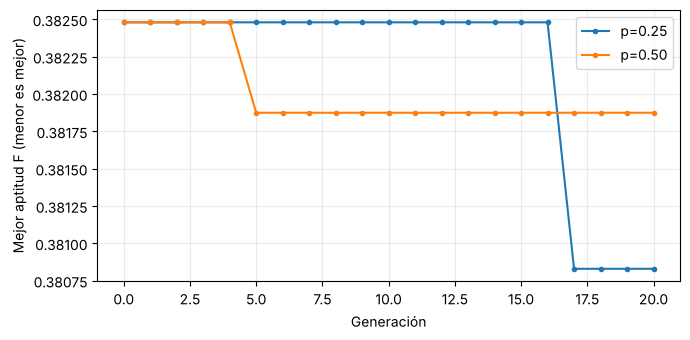

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Conserva la interpretación de tu equipo en una celda: identifica el parámetro cambiado; compara el mejor $F$, el agua potable y la factibilidad; explica una meseta o mejora; y delimita lo que puedes concluir de dos ejecuciones. Si los resultados coinciden, explica esa coincidencia con la misma validez. La variación no necesita ganar.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [20]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.